# Setup

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

from pathlib import Path
from copy import deepcopy
import multiprocessing as mp
import logging
import random

import mlflow
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import numpy as np
from dotenv import load_dotenv

from halcyon.results.manipulate_results_df import (create_tidy_df_from_mlflow_runs, 
                                                   split_df_into_single_and_double_ko,
                                                   add_model_name_to_df,
                                                       df_with_ground_truth_as_kind_of_model)

from halcyon.results.plot_from_df import plot_model_plots, plot_per_gene_mse_heatmap, rotate_x_tick_labels, wrap_titles

from halcyon.results import DfColumnNames

seed = 174
# for CPU
torch.manual_seed(seed)              
# for all GPUs
torch.cuda.manual_seed_all(seed)     
np.random.seed(seed) 
random.seed(seed) 

load_dotenv() 

logging.basicConfig(
    level=logging.INFO, 
    format='%(asctime)s - %(levelname)s - %(message)s',
    force=True  # Important in Jupyter to reset config
)

# Load from MLFlow

In [2]:
print(mlflow.get_tracking_uri())
[f"{experiment.name=}" for experiment in mlflow.search_experiments()]
mlflow.set_experiment("Halcyon sandbox experiment")
mlflow.set_experiment_tag("Tool name", "HALCYON") 

https://mlflow.cropresilience.org


Get the ID of the (parent) simulation run

In [23]:
simulation_run_id_to_use = "8f557eb8aadd45fdba24175cc74672c3"

run = mlflow.get_run(simulation_run_id_to_use)

params = run.data.params
print(params)
print(run.data.tags.get('mlflow.source.git.commit'))

{'nr_genes': '20', 'sparsity': '0.1', 'num_modules': '2', 'noise_level': 'LOW', 'seed': '174'}
None


In [24]:
parent_run_id_search_string = f"tags.mlflow.parentRunId= '{simulation_run_id_to_use}'" 
runs_to_download = mlflow.search_runs(filter_string=parent_run_id_search_string, output_format="list")

In [25]:
runs_to_download[0].data.params

{'hidden_size': '10',
 'synthesis_only_positive': 'True',
 'lr': '0.01',
 'patience': '10',
 'min_delta': '1e-05',
 'nr_epochs': '5',
 'batch_size': '16',
 'loss_fn': 'MSELossFlexible',
 'model_class': 'PhoenixAddAndProdLayers'}

In [26]:
raw_df_download = create_tidy_df_from_mlflow_runs(runs_to_download)
with_model_name = add_model_name_to_df(raw_df_download)

2026-03-12 12:50:59,629 - INFO - Downloading artifacts for run 7f4f07391d9d493a9ca208b6a11b1f56


2026-03-12 12:51:00,622 - INFO - Getting model name for run_id 7f4f07391d9d493a9ca208b6a11b1f56


## Make subsets of data for plotting

In [27]:
# Split into Single and Double knockout
tidy_df_single_ko, tidy_df_double_ko = split_df_into_single_and_double_ko(with_model_name)
tidy_df_single_ko['condition'].value_counts()

condition
KO: Node_3. Env: None     420
KO: Node_1. Env: None     420
KO: Node_18. Env: None    420
KO: Node_9. Env: None     420
KO: Node_13. Env: None    420
KO: Node_6. Env: None     420
KO: Node_16. Env: None    420
KO: Node_4. Env: None     420
KO: Node_2. Env: None     420
KO: Node_10. Env: None    420
KO: Node_17. Env: None    420
KO: Node_5. Env: None     420
KO: Node_8. Env: None     420
KO: Node_12. Env: None    420
KO: Node_7. Env: None     420
KO: Node_11. Env: None    420
KO: Node_14. Env: None    420
KO: Node_15. Env: None    420
KO: Node_0. Env: None     420
KO: Node_19. Env: None    420
Name: count, dtype: int64

In [28]:
tidy_df_single_ko[DfColumnNames.MODEL_COL].value_counts()

model
hidden_size_10__synthesis_only_positive_True__lr_0.01__patience_10__min_delta_1e-05__nr_epochs_5__batch_size_16__loss_fn_MSELossFlexible__model_class_PhoenixAddAndProdLayers    8400
Name: count, dtype: int64

In [29]:
def df_selection_function(df):
    node_index_regex = '|'.join([f'{i}' for i in range(4)])
    genes_to_show_regex = rf"Node_(?:{node_index_regex})(?:[.,]|$)"

    models_to_show = ["PhoenixAddAndProdLayers", "PyTorchODE", DfColumnNames.GROUND_TRUTH_COL, "HybridModel"]
    models_to_show_regex = "|".join(models_to_show)

    index_to_select = ((df[DfColumnNames.GENE_COL].str.contains(genes_to_show_regex))
            & (df[DfColumnNames.CONDITION_COL].str.contains(genes_to_show_regex))
            & (df[DfColumnNames.MODEL_COL].str.contains(models_to_show_regex)))
    filtered_df =  df[index_to_select]
    assert len(filtered_df), 'Filtered dataframe is empty'
    return filtered_df

In [30]:
df_selection_function(tidy_df_single_ko).sum()

gene                    Node_0Node_1Node_2Node_3Node_0Node_1Node_2Node...
time                                                                168.0
predicted_expression                                           208.736816
ground_truth                                                   150.848846
condition               KO: Node_3. Env: NoneKO: Node_3. Env: NoneKO: ...
run_id                  7f4f07391d9d493a9ca208b6a11b1f567f4f07391d9d49...
model                   hidden_size_10__synthesis_only_positive_True__...
dtype: object

In [31]:
filtered_df_single_ko = df_selection_function(tidy_df_single_ko)
filtered_df_double_ko = df_selection_function(tidy_df_double_ko)

# Plotting

## Lineplots

### Single KO

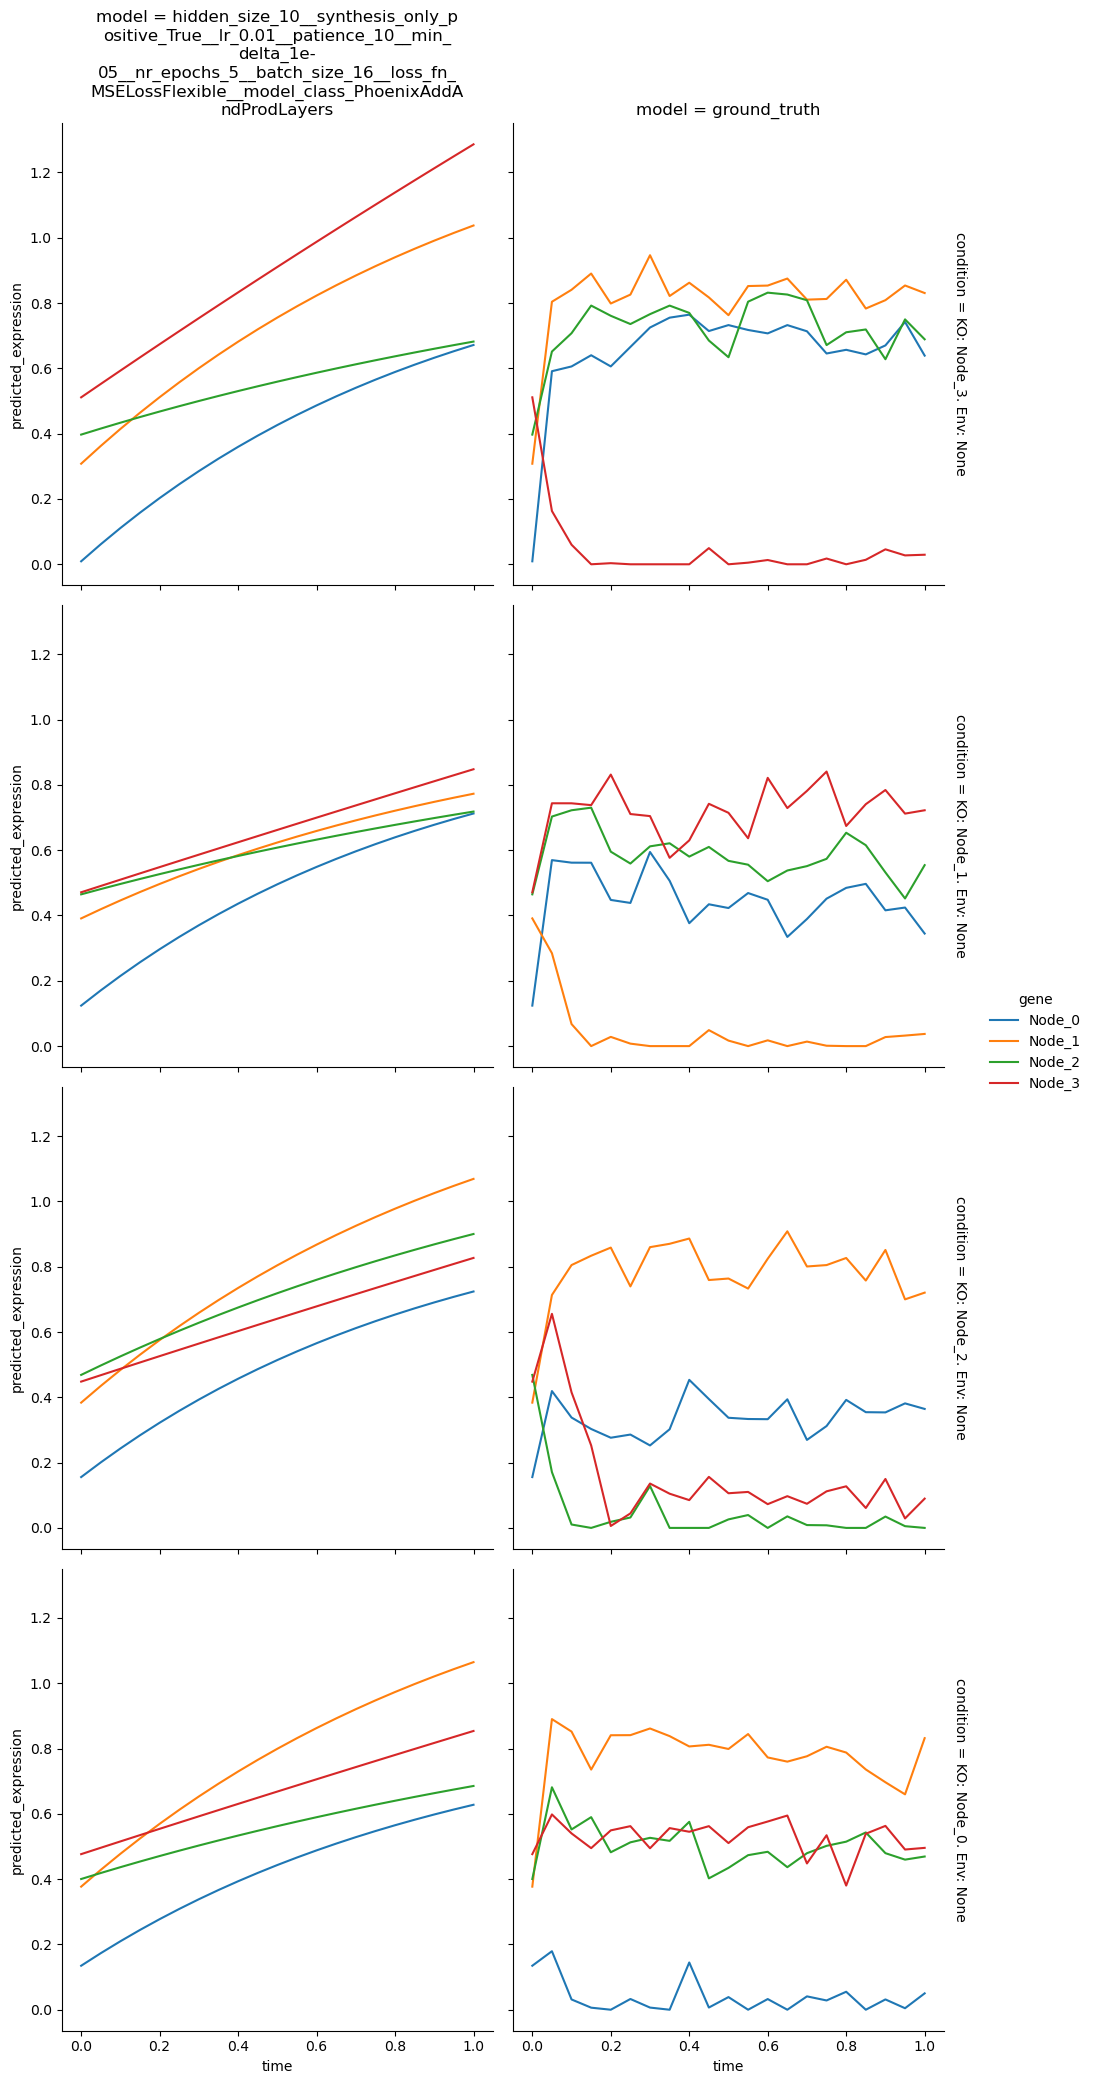

In [32]:
# FOr each of this knockout, plot predicted vs real for all model (for subset of genes)

# Plot for single KO
g = plot_model_plots(filtered_df_single_ko)
wrap_titles(g)

### Double KO

In [ ]:
g = plot_model_plots(filtered_df_double_ko)
wrap_titles(g)

## Now the heatmaps

### Single KO

In [ ]:
from matplotlib.colors import Normalize

In [ ]:
# Calculate the MSE heatmap that we've shown before
g = plot_per_gene_mse_heatmap(tidy_df_single_ko, robust_cmap=False)
wrap_titles(g)

### Double KO

In [ ]:
# Calculate the MSE heatmap that we've shown before
g = plot_per_gene_mse_heatmap(tidy_df_double_ko, robust_cmap=False)
wrap_titles(g)